# Predicting Heating Load

Can building geometry and glazing estimate the Heating Load produced by a building simulation?
We compare Linear Regression, Decision Tree, Random Forest and XGBoost, tune the last two,
and select using training-only cross-validation. The final test set is used only after selection.

This notebook contains every modelling step. Run it from the repository root after installing
`requirements.txt`. It does not import `train.py` or write the serving model.

Data: Tsanas & Xifara (2012), [UCI Energy Efficiency](https://doi.org/10.24432/C51307), CC BY 4.0.
The eight inputs describe geometry, orientation and glazing. Y1 is Heating Load;
Y2 is excluded. Values are in dataset target units, not assumed energy-bill units.

In [1]:
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

ROOT = Path.cwd()
SEED = 42
FEATURES = [
    "relative_compactness", "surface_area", "wall_area", "roof_area",
    "overall_height", "orientation", "glazing_area", "glazing_area_distribution",
]
CATEGORICAL = ["orientation", "glazing_area_distribution"]
NUMERIC = [name for name in FEATURES if name not in CATEGORICAL]


import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")

## 1. Load and inspect

Keep the original workbook. Select X1–X8 and Y1 explicitly, then give them readable names.
Structural checks inspect the source; plots and exploratory relationships below use training rows only.
No imputation is needed if the missing-value counts are zero.

In [2]:
data = pd.read_excel(ROOT / "data/ENB2012_data.xlsx")
data = data[[f"X{i}" for i in range(1, 9)] + ["Y1"]].copy()
data.columns = FEATURES + ["heating_load"]
if data.isna().any().any() or data.duplicated().any():
    raise ValueError("Inspect missing or duplicate rows before training.")

print("Shape:", data.shape)
display(data.dtypes.to_frame("dtype"))
display(data.isna().sum().to_frame("missing"))
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate predictor rows:", data[FEATURES].duplicated().sum())
display(data.head())

Shape: (768, 9)


,dtype
relative_compactness,float64
surface_area,float64
wall_area,float64
roof_area,float64
overall_height,float64
orientation,int64
glazing_area,float64
glazing_area_distribution,int64
heating_load,float64


,missing
relative_compactness,0
surface_area,0
wall_area,0
roof_area,0
overall_height,0
orientation,0
glazing_area,0
glazing_area_distribution,0
heating_load,0


Duplicate rows: 0
Duplicate predictor rows: 0


,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84


## 2. Reserve the test set

Use an 80/20 split with seed 42: 614 training and 154 test observations.
Five shuffled training folds use the same seed for every comparison. The test target never guides tuning.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    data[FEATURES], data.heating_load, test_size=0.2, random_state=SEED,
)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Training: {len(X_train)}; test: {len(X_test)}")
training = X_train.assign(heating_load=y_train)

Training: 614; test: 154


## 3. Explore training data

Look for skew, ranges, categorical differences and redundant predictors. Orientation and glazing
distribution are category codes, so their numeric labels do not imply a linear distance.

,count,mean,std,min,25%,50%,75%,max
relative_compactness,614.0,0.761678,0.105424,0.62,0.6600,0.74,0.820,0.98
surface_area,614.0,673.829805,88.161209,514.50,612.5000,686.00,759.500,808.50
wall_area,614.0,318.819218,43.335953,245.00,294.0000,318.50,343.000,416.50
roof_area,614.0,177.505293,44.960238,110.25,147.0000,220.50,220.500,220.50
overall_height,614.0,5.221498,1.751195,3.50,3.5000,3.50,7.000,7.00
orientation,614.0,3.511401,1.108635,2.00,3.0000,4.00,4.000,5.00
glazing_area,614.0,0.235423,0.134152,0.00,0.1000,0.25,0.400,0.40
glazing_area_distribution,614.0,2.799674,1.551908,0.00,1.2500,3.00,4.000,5.00
heating_load,614.0,22.155033,10.054280,6.01,12.9775,18.25,31.545,43.10


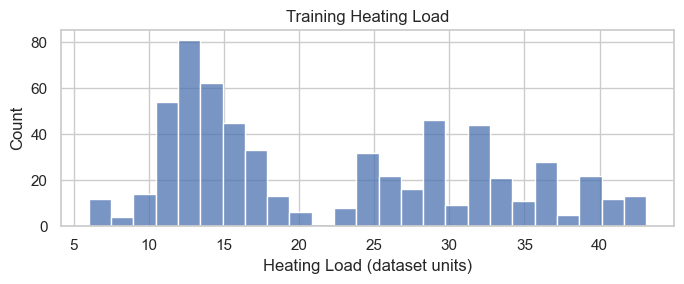

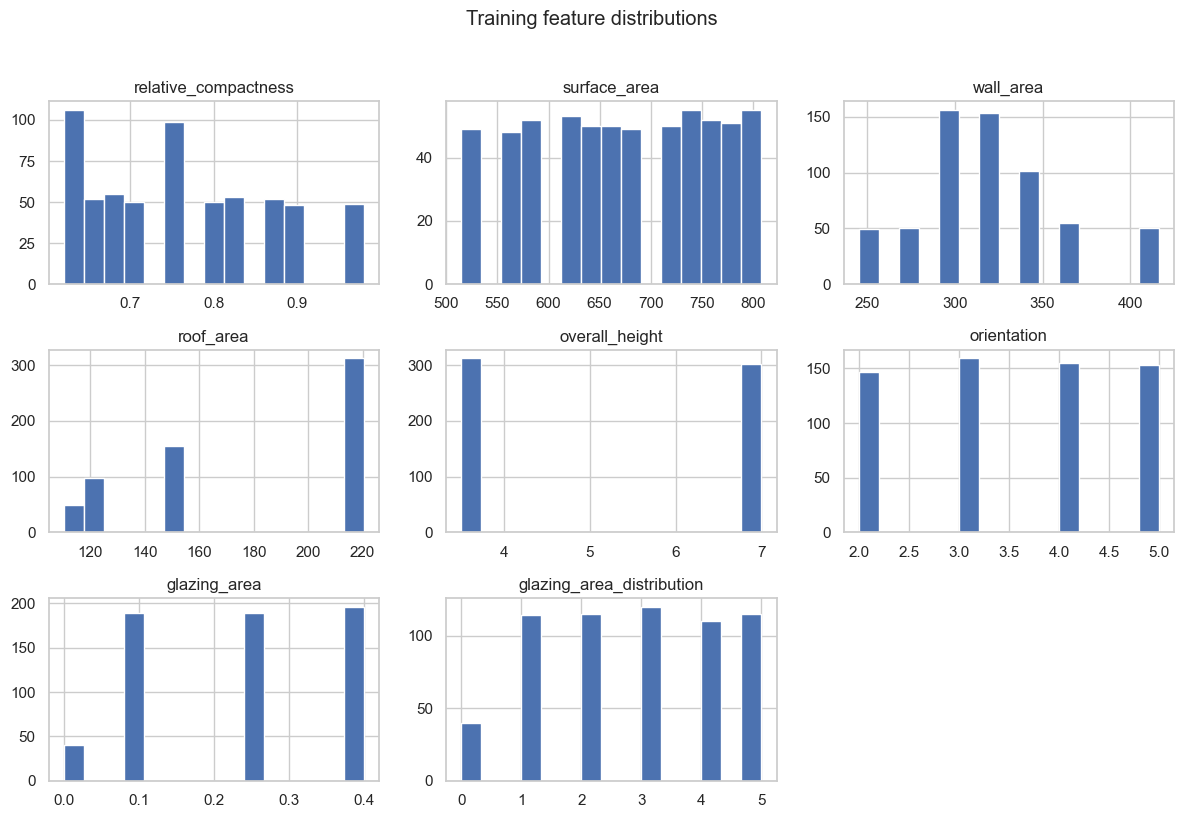

In [4]:
display(training.describe().T)
fig, ax = plt.subplots(figsize=(7, 3))
sns.histplot(y_train, bins=25, ax=ax)
ax.set(title="Training Heating Load", xlabel="Heating Load (dataset units)")
plt.tight_layout()
plt.show()
X_train.hist(figsize=(12, 8), bins=15)
plt.suptitle("Training feature distributions", y=1.02)
plt.tight_layout()
plt.show()

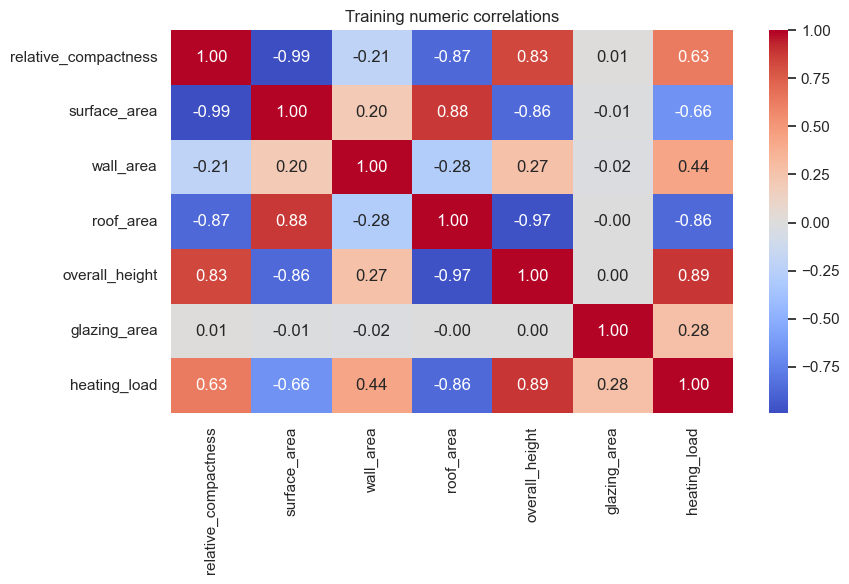

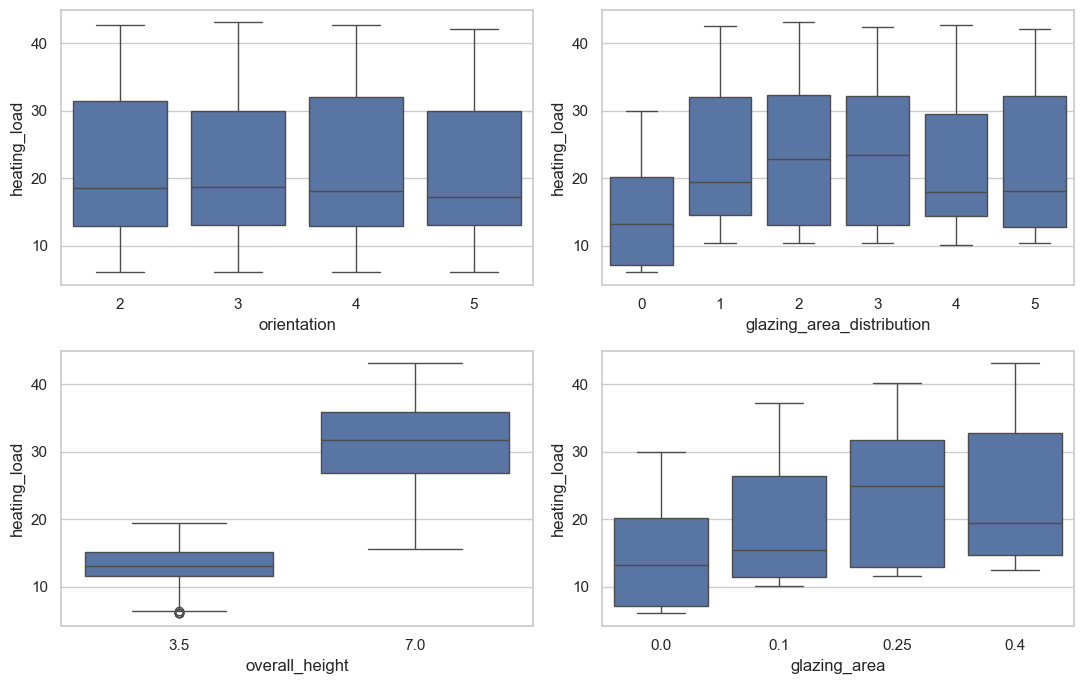

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(training[NUMERIC + ["heating_load"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=ax)
ax.set_title("Training numeric correlations")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for feature, ax in zip(["orientation", "glazing_area_distribution", "overall_height", "glazing_area"], axes.flat):
    sns.boxplot(data=training, x=feature, y="heating_load", ax=ax)
plt.tight_layout()
plt.show()

Relative compactness and surface area encode strongly related geometry; height and roof area
also overlap. Height and glazing show clearer target differences than orientation. These relationships
motivate comparing a linear model with trees that capture nonlinear effects. Correlations describe
this simulation dataset and do not establish causal effects.

## 4. Leakage-free preprocessing

One-hot encode both categorical features. Scale continuous inputs for Linear Regression;
trees use their original scale. A Pipeline keeps preprocessing inside each training fold.
The small function below only avoids repeating the same preprocessing four times.

In [6]:
def make_pipeline(name, estimator):
    # Encoders and scalers learn only from each fold's training rows.
    preprocess = ColumnTransformer([
        ("numeric", StandardScaler() if name == "linear" else "passthrough", NUMERIC),
        ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    return Pipeline([("preprocess", preprocess), ("model", estimator)])

## 5. Compare four initial models

RMSE penalizes large errors and is expressed in target units; lower is better.
scikit-learn returns negative RMSE for scoring, so we negate it for display.
The standard deviation describes variation across five folds.

In [7]:
estimators = {
    "linear": LinearRegression(),
    "decision_tree": DecisionTreeRegressor(random_state=SEED),
    "random_forest": RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1),
    "xgboost": XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.1,
        objective="reg:squarederror", tree_method="hist", device="cpu",
        random_state=SEED, n_jobs=1),
}
pipelines = {name: make_pipeline(name, model) for name, model in estimators.items()}
baseline = {}
for name, pipeline in pipelines.items():
    scores = -cross_val_score(pipeline, X_train, y_train, cv=cv,
                             scoring="neg_root_mean_squared_error", n_jobs=1)
    baseline[name] = {"cv_rmse": float(scores.mean()), "cv_std": float(scores.std())}
    print(name, baseline[name], flush=True)


display(pd.DataFrame(baseline).T.rename_axis("model"))

linear {'cv_rmse': 2.828453196914384, 'cv_std': 0.1235495113826791}


decision_tree {'cv_rmse': 0.6472078080939344, 'cv_std': 0.1113035844062299}


random_forest {'cv_rmse': 0.5359458221419935, 'cv_std': 0.03397304139145991}


xgboost {'cv_rmse': 0.4357994290374075, 'cv_std': 0.027593009507552415}


,cv_rmse,cv_std
model,,
linear,2.828453,0.123550
decision_tree,0.647208,0.111304
random_forest,0.535946,0.033973
xgboost,0.435799,0.027593


## 6. Tune Random Forest and XGBoost

Try six forest combinations and twelve XGBoost combinations. Depth controls tree complexity;
minimum leaf size smooths the forest. XGBoost learning rate and tree count work together.
All searches use the same five training folds. A tuned configuration replaces its baseline only
if its CV RMSE is at least as good. Tuning scores are selection estimates, not independent test scores.

In [8]:
grids = {
    "random_forest": {"model__max_depth": [8, None], "model__min_samples_leaf": [1, 2, 4]},
    "xgboost": {"model__max_depth": [2, 3, 4], "model__learning_rate": [0.03, 0.1],
                "model__n_estimators": [100, 300]},
}
tuned = {}
candidates = {name: clone(pipeline) for name, pipeline in pipelines.items()}
selection_scores = {name: row["cv_rmse"] for name, row in baseline.items()}
for name, grid in grids.items():
    search = GridSearchCV(pipelines[name], grid, cv=cv,
                          scoring="neg_root_mean_squared_error", n_jobs=1, error_score="raise")
    search.fit(X_train, y_train)
    table = pd.DataFrame(search.cv_results_)
    table["cv_rmse"] = -table["mean_test_score"]
    display(table[["params", "cv_rmse", "std_test_score"]].sort_values("cv_rmse"))
    tuned[name] = {"cv_rmse": float(-search.best_score_), "parameters": search.best_params_}
    print(name, tuned[name], flush=True)
    if tuned[name]["cv_rmse"] <= selection_scores[name]:
        candidates[name] = search.best_estimator_
        selection_scores[name] = tuned[name]["cv_rmse"]

,params,cv_rmse,std_test_score
0,"{'model__max_depth': 8, 'model__min_samples_le...",0.528083,0.033228
3,"{'model__max_depth': None, 'model__min_samples...",0.535946,0.033973
1,"{'model__max_depth': 8, 'model__min_samples_le...",0.577049,0.023342
4,"{'model__max_depth': None, 'model__min_samples...",0.581144,0.024288
5,"{'model__max_depth': None, 'model__min_samples...",0.731869,0.119696
2,"{'model__max_depth': 8, 'model__min_samples_le...",0.732058,0.119582


random_forest {'cv_rmse': 0.5280825911645182, 'parameters': {'model__max_depth': 8, 'model__min_samples_leaf': 1}}


,params,cv_rmse,std_test_score
11,"{'model__learning_rate': 0.1, 'model__max_dept...",0.398615,0.038105
10,"{'model__learning_rate': 0.1, 'model__max_dept...",0.435453,0.039326
9,"{'model__learning_rate': 0.1, 'model__max_dept...",0.435799,0.027593
5,"{'model__learning_rate': 0.03, 'model__max_dep...",0.447241,0.041627
7,"{'model__learning_rate': 0.1, 'model__max_dept...",0.480826,0.055154
8,"{'model__learning_rate': 0.1, 'model__max_dept...",0.504031,0.042787
3,"{'model__learning_rate': 0.03, 'model__max_dep...",0.538358,0.042127
6,"{'model__learning_rate': 0.1, 'model__max_dept...",0.632876,0.081614
1,"{'model__learning_rate': 0.03, 'model__max_dep...",0.703059,0.081531
4,"{'model__learning_rate': 0.03, 'model__max_dep...",0.999063,0.060183


xgboost {'cv_rmse': 0.3986153384094746, 'parameters': {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 300}}


## 7. Freeze selection, then evaluate once

Choose the lowest CV RMSE across families, using the original family order for an exact tie.
Fit the chosen pipeline on the 614 training rows and evaluate the untouched test set.
Do not refit on all 768 rows or change choices after inspecting these results.

In [9]:
# Dict order breaks exact ties. Test results never choose the winner.
selected = min(selection_scores, key=selection_scores.get)
model = candidates[selected].fit(X_train, y_train)
predictions = model.predict(X_test)
metrics = {
    "rmse": float(root_mean_squared_error(y_test, predictions)),
    "mae": float(mean_absolute_error(y_test, predictions)),
    "r2": float(r2_score(y_test, predictions)),
}
selected_params = {key: value for key, value in model.get_params().items()
                   if key in grids.get(selected, {})}
results = {"seed": SEED, "train_rows": len(X_train), "test_rows": len(X_test),
           "baseline": baseline, "tuned": tuned, "selected_model": selected,
           "selected_parameters": selected_params, "selected_cv_rmse": selection_scores[selected],
           "test_metrics": metrics}

print("Selected:", selected)
print("Parameters:", selected_params)
display(pd.Series(metrics, name="test score").to_frame())

Selected: xgboost
Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 300}


,test score
rmse,0.403917
mae,0.289649
r2,0.998435


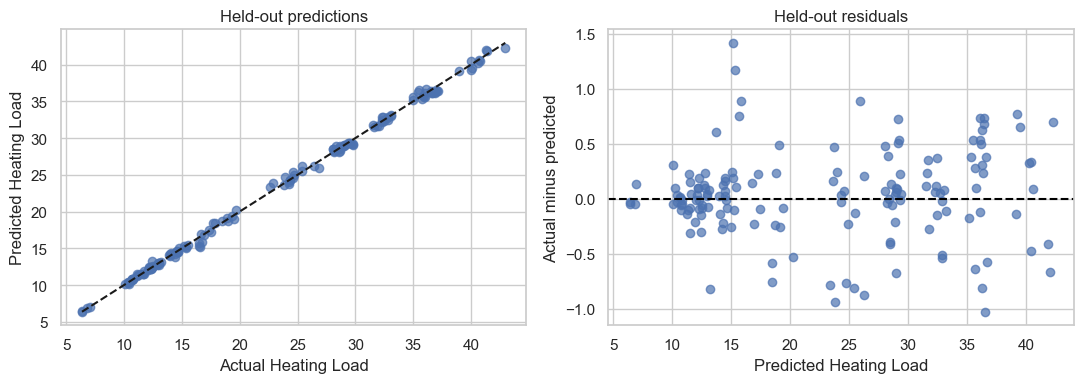

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, predictions, alpha=0.7)
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].plot(limits, limits, "k--")
axes[0].set(xlabel="Actual Heating Load", ylabel="Predicted Heating Load", title="Held-out predictions")
axes[1].scatter(predictions, y_test - predictions, alpha=0.7)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Predicted Heating Load", ylabel="Actual minus predicted", title="Held-out residuals")
plt.tight_layout()
plt.show()

## 8. Explain the frozen model

Shuffle one original input at a time and measure the increase in test RMSE (five repeats).
This is a post-selection explanation only: it will not drive further tuning or feature removal.
Correlated predictors can substitute for each other, and shuffling can create unrealistic combinations.
Low importance is not evidence that a building property is physically irrelevant.

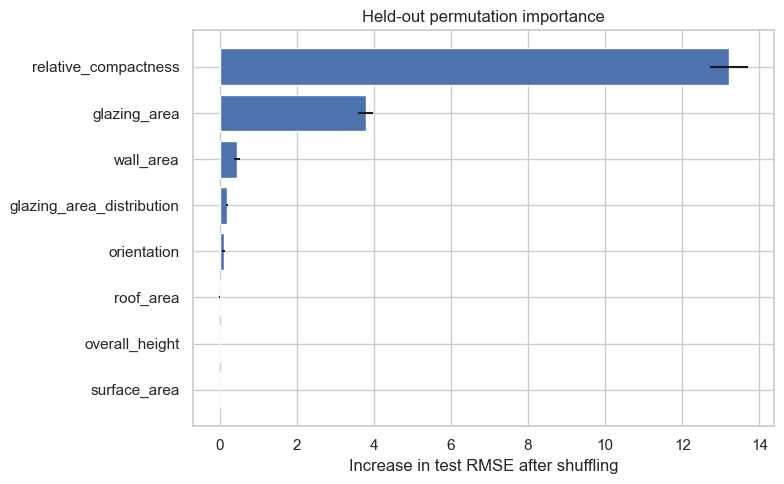

In [11]:
importance = permutation_importance(model, X_test, y_test, n_repeats=5,
    scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=1)
order = np.argsort(importance.importances_mean)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(np.array(FEATURES)[order], importance.importances_mean[order],
        xerr=importance.importances_std[order])
ax.set(xlabel="Increase in test RMSE after shuffling", title="Held-out permutation importance")
plt.tight_layout()
plt.show()

## 9. Reproduce and interpret

`python train.py` independently repeats the same modelling recipe and saves a fitted pipeline
and `results.json`. Serving loads that pipeline, so requests receive the same preprocessing.
The notebook leaves those files unchanged.

**Random-split limitation:** the source contains 12 simulated building geometries with related
orientation/glazing variants. Random splitting places variants of familiar geometries on both sides.
Strong scores therefore describe interpolation within these simulations, not demonstrated accuracy
for unfamiliar geometries, climates or real buildings. Weather, occupancy and measured energy use
are absent. The API has not been validated for HVAC design or energy-billing use.

The split and model choices are fixed for reproducibility. Re-running this notebook is reproduction,
not permission to repeatedly optimize against test errors.